**This notebook walks you through the process of fine-tuning a Segment Anything Model (SAM) using custom data**.
<p>

**What is SAM?**
<br>
SAM is an image segmentation model developed by Meta AI. It was trained over 11 billion segmentation masks from millions of images. It is designed to take human prompts, in the form of points, bounding boxes or even a text prompt describing what should be segmented.
<p>

**What are the key features of SAM?**
<br>

* **Zero-shot generalization:** SAM can be used to segment objects that it has never seen before, without the need for additional training.

* **Flexible prompting:** SAM can be prompted with a variety of input, including points, boxes, and text descriptions.

* **Real-time mask computation:** SAM can generate masks for objects in real time. This makes SAM ideal for applications where it is necessary to segment objects quickly, such as autonomous driving and robotics.

* **Ambiguity awareness:** SAM is aware of the ambiguity of objects in images. This means that SAM can generate masks for objects even when they are partially occluded or overlapping with other objects.

<p>

**How does SAM work?**
<br>
SAM works by first encoding the image into a high-dimensional vector representation. The prompt is encoded into a separate vector representation. The two vector representations are then combined and passed to a mask decoder, which outputs a mask for the object specified by the prompt.
<p>
The image encoder is a vision transformer (ViT-H) model, which is a large language model that has been pre-trained on a massive dataset of images. The prompt encoder is a simple text encoder that converts the input prompt into a vector representation. The mask decoder is a lightweight transformer model that predicts the object mask from the image and prompt embeddings.
<p>

**SAM paper:** https://arxiv.org/pdf/2304.02643.pdf​
<p>

<p>

This code has been heavily adapted from this notebook but modified to work with a truly custom dataset where we have a bunch of images and binary masks.
https://github.com/NielsRogge/Transformers-Tutorials/blob/master/SAM/Fine_tune_SAM_(segment_anything)_on_a_custom_dataset.ipynb



In [ ]:
# Install the required libraries
#SAM
!pip install git+https://github.com/facebookresearch/segment-anything.git
#Transformers
!pip install -q git+https://github.com/huggingface/transformers.git
#Datasets to prepare data
!pip install datasets

  Cloning https://github.com/facebookresearch/segment-anything.git to /tmp/pip-req-build-ax7h24nj
  Running command git clone --filter=blob:none --quiet https://github.com/facebookresearch/segment-anything.git /tmp/pip-req-build-ax7h24nj
  Resolved https://github.com/facebookresearch/segment-anything.git to commit dca509fe793f601edb92606367a655c15ac00fdf
  Preparing metadata (setup.py) ... done
  Created wheel for segment_anything: filename=segment_anything-1.0-py3-none-any.whl size=36592 sha256=62ef55cf999e829d98aac83a90e0ec15f47016288bd4b83b9ca7637837e0ff95
  Stored in directory: /tmp/pip-ephem-wheel-cache-c4ko5bp6/wheels/15/d7/bd/05f5f23b7dcbe70cbc6783b06f12143b0cf1a5da5c7b52dcc5
Successfully built segment_anything
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 491.2/491.2 kB 35.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 

In [ ]:
!pip install monai

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 75.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.3/18.3 MB 106.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 77.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 47.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 46.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 14.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2

In [ ]:
import torch
print(torch.cuda.is_available())  # Should return True
print(torch.__version__)  # Should return correct version


True
2.6.0+cu124


In [ ]:
pip list | grep nvidia


nvidia-cublas-cu12                 12.4.5.8
nvidia-cuda-cupti-cu12             12.4.127
nvidia-cuda-nvcc-cu12              12.5.82
nvidia-cuda-nvrtc-cu12             12.4.127
nvidia-cuda-runtime-cu12           12.4.127
nvidia-cudnn-cu12                  9.1.0.70
nvidia-cufft-cu12                  11.2.1.3
nvidia-curand-cu12                 10.3.5.147
nvidia-cusolver-cu12               11.6.1.9
nvidia-cusparse-cu12               12.3.1.170
nvidia-cusparselt-cu12             0.6.2
nvidia-ml-py                       12.570.86
nvidia-nccl-cu12                   2.21.5
nvidia-nvcomp-cu12                 4.2.0.11
nvidia-nvjitlink-cu12              12.4.127
nvidia-nvtx-cu12                   12.4.127


In [ ]:
pip uninstall nvidia-cuda-nvcc-cu12 -y


Found existing installation: nvidia-cuda-nvcc-cu12 12.5.82
Uninstalling nvidia-cuda-nvcc-cu12-12.5.82:
  Successfully uninstalled nvidia-cuda-nvcc-cu12-12.5.82


In [ ]:
pip install nvidia-cuda-nvcc-cu12==12.4.127


ERROR: Could not find a version that satisfies the requirement nvidia-cuda-nvcc-cu12==12.4.127 (from versions: 0.0.1.dev5, 12.0.76, 12.0.140, 12.1.66, 12.1.105, 12.2.91, 12.2.128, 12.2.140, 12.3.52, 12.3.103, 12.3.107, 12.4.99, 12.4.131, 12.5.40, 12.5.82, 12.6.20, 12.6.68, 12.6.77, 12.6.85, 12.8.61, 12.8.93)
ERROR: No matching distribution found for nvidia-cuda-nvcc-cu12==12.4.127


In [ ]:
pip install nvidia-cuda-nvcc-cu12==12.4.131


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 22.3/22.3 MB 1.7 MB/s eta 0:00:00


In [ ]:
import os
import random
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import tifffile as tiff
from PIL import Image
import matplotlib.pyplot as plt

In [ ]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# === STEP 2: SET DATASET PATHS ===
IMAGE_FOLDER = "/content/drive/My Drive/Antarctic_Icebergs/icebergs_unmasked"  # Update path
MASK_FOLDER = "/content/drive/My Drive/Antarctic_Icebergs/icebergs_masked"  # Update path


In [ ]:
# === STEP 3: IMAGE PREPROCESSING ===
IMG_SIZE = (256, 256)  # Resize all images to this size

In [ ]:
augmentations = transforms.Compose([
       transforms.RandomHorizontalFlip(),        # Flips image horizontally
       transforms.RandomVerticalFlip(),          # Flips image vertically
       transforms.RandomRotation(degrees=20),    # Rotates image randomly
       transforms.ColorJitter(brightness=0.2,   # Adjusts brightness, contrast, etc.
                              contrast=0.2,
                              saturation=0.2,
                              hue=0.1),
       transforms.RandomResizedCrop(size=IMG_SIZE, scale=(0.8, 1.0)),  # Randomly crops and resizes
   ])

In [ ]:
# Define transformation: Convert to tensor, resize, and normalize
image_transform = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.ToTensor(),
])

mask_transform = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.ToTensor(),
])

In [ ]:
# === STEP 4: CUSTOM DATASET CLASS ===
class IcebergDataset(Dataset):
         def __init__(self, image_dir, mask_dir, transform_img=None, transform_mask=None, augmentations=None):
        self.image_dir = image_dir
        self.mask_dir = mask_dir
        self.image_filenames = sorted(os.listdir(image_dir))  # Sort to match image-mask pairs
        self.mask_filenames = sorted(os.listdir(mask_dir))  #sorts alphabetically then pairs
        self.transform_img = transform_img
        self.transform_mask = transform_mask
        self.augmentations = augmentations

    def __len__(self):
        return len(self.image_filenames)

    def __getitem__(self, idx):
        img_path = os.path.join(self.image_dir, self.image_filenames[idx])
        mask_path = os.path.join(self.mask_dir, self.mask_filenames[idx])

        # Load images (handling different formats)
        if img_path.endswith(".tif") or img_path.endswith(".tiff"):
            image = tiff.imread(img_path)
        else:
            image = Image.open(img_path).convert("RGB")  # Convert to RGB

        if mask_path.endswith(".tif") or mask_path.endswith(".tiff"):
            mask = tiff.imread(mask_path)
        else:
            mask = Image.open(mask_path).convert("L")  # Convert mask to grayscale

        if self.augmentations:
                 # Apply augmentations to both image and mask simultaneously
                 augmented = self.augmentations(image=image, mask=mask)
                 image = augmented['image']
                 mask = augmented['mask']

        # **Fix TypeError: Convert uint16 to uint8**
        if image.dtype == np.uint16:
            image = (image / 256).astype(np.uint8)  # Normalize to 0-255 range
        if mask.dtype == np.uint16:
            mask = (mask / 256).astype(np.uint8)

        # Convert to PIL for transformations
        image = Image.fromarray(image)
        mask = Image.fromarray(mask)

        # Apply transformations
        if self.transform_img:
            image = self.transform_img(image)
        if self.transform_mask:
            mask = self.transform_mask(mask)

        return {"image": image, "label": mask}


In [ ]:
augmented_dataset = IcebergDataset(IMAGE_FOLDER, MASK_FOLDER,
                                      image_transform, mask_transform,
                                      augmentations=augmentations)

In [ ]:
augmented_dataloader = DataLoader(augmented_dataset, batch_size=4, shuffle=True)

In [ ]:
# === STEP 5: LOAD DATASET ===
dataset = IcebergDataset(IMAGE_FOLDER, MASK_FOLDER, image_transform, mask_transform)
dataloader = DataLoader(dataset, batch_size=4, shuffle=True)

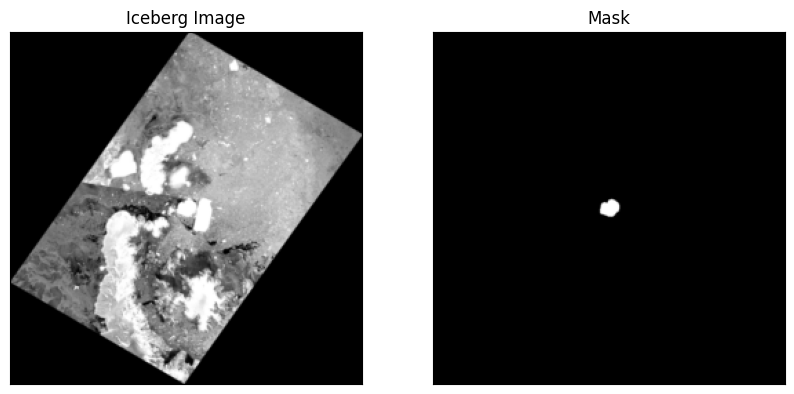

In [ ]:
# === STEP 6: DISPLAY SAMPLE IMAGES ===
def show_sample_images(dataset):
    img_num = random.randint(0, len(dataset) - 1)
    example_image = dataset[img_num]["image"]
    example_mask = dataset[img_num]["label"]

    fig, axes = plt.subplots(1, 2, figsize=(10, 5))

    # Plot the image
    axes[0].imshow(example_image.permute(1, 2, 0))  # Convert from (C, H, W) to (H, W, C)
    axes[0].set_title("Iceberg Image")

    # Plot the mask
    axes[1].imshow(example_mask.squeeze(), cmap="gray")  # Squeeze to remove extra dimensions
    axes[1].set_title("Mask")

    # Hide axis ticks and labels
    for ax in axes:
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_xticklabels([])
        ax.set_yticklabels([])

    plt.show()

# Display sample images
show_sample_images(dataset)

Get bounding boxes from masks. You can get here directly if you are working with coco style annotations where bounding boxes are captured in a JSON file.

In [ ]:
def get_bounding_box(mask):


    # Ensure the mask is 2D
    mask = mask.squeeze()  # Remove unnecessary dimensions
    if mask.ndim != 2:
        raise ValueError("Mask must be a 2D array after squeezing")

    # Find nonzero pixel locations
    y_indices, x_indices = np.where(mask > 0)

    # If no object is detected, return None
    if len(x_indices) == 0 or len(y_indices) == 0:
        return None

    # Get bounding box coordinates
    x_min, x_max = np.min(x_indices), np.max(x_indices)
    y_min, y_max = np.min(y_indices), np.max(y_indices)

    # Add perturbation to bounding box coordinates
    H, W = mask.shape
    x_min = max(0, x_min - np.random.randint(0, 20))
    x_max = min(W, x_max + np.random.randint(0, 20))
    y_min = max(0, y_min - np.random.randint(0, 20))
    y_max = min(H, y_max + np.random.randint(0, 20))

    bbox = [x_min, y_min, x_max, y_max]
    return bbox

    # load ground truth segmentation
idx = 5  # Choose an appropriate index
ground_truth_seg = np.array(dataset[idx]["label"])

input_boxes = get_bounding_box(ground_truth_seg)
input_boxes

[97, 95, 138, 155]

In [ ]:
sample_data = dataset[idx]  # Get the first sample
image = sample_data["image"]

# Convert image tensor to numpy array for plotting (if necessary)
image = image.permute(1, 2, 0).cpu().numpy()

In [ ]:
def show_box(box, ax):
    x0, y0 = box[0], box[1]
    w, h = box[2] - box[0], box[3] - box[1]
    ax.add_patch(plt.Rectangle((x0, y0), w, h, edgecolor='green', facecolor=(0,0,0,0), lw=2))

def show_boxes_on_image(raw_image, boxes):
    plt.figure(figsize=(10,10))
    plt.imshow(raw_image)
    for box in boxes:
      show_box(box, plt.gca())
    plt.axis('on')
    plt.show()

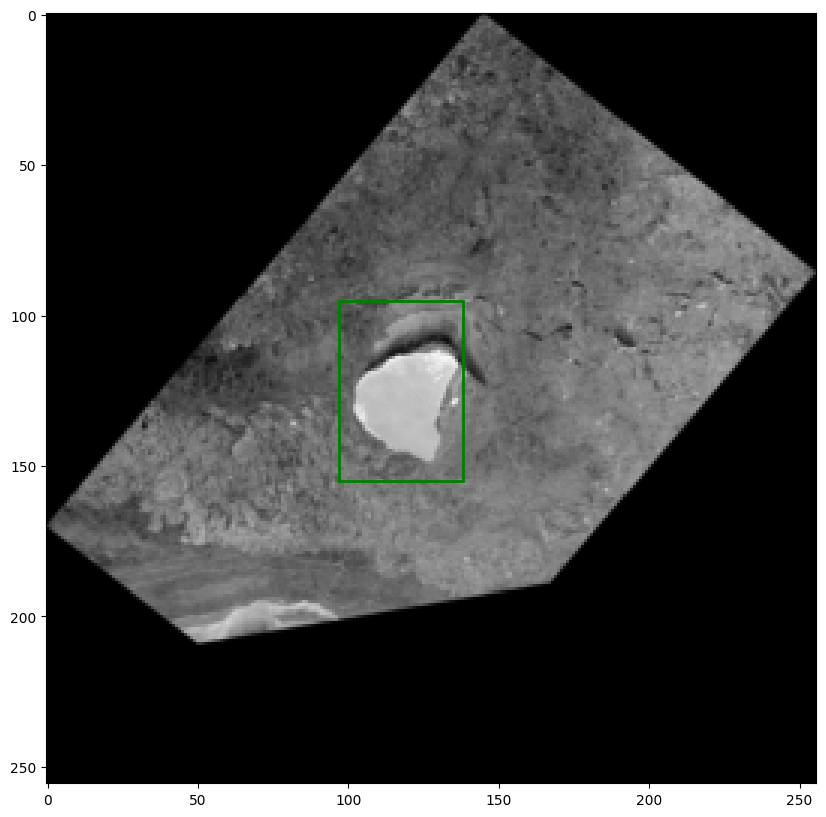

In [ ]:
show_boxes_on_image(image, [input_boxes])

In [ ]:
class IcebergSAMDataset(Dataset):

    def __init__(self, dataset, processor):
        self.dataset = dataset
        self.processor = processor

    # returns length of dataset
    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        item = self.dataset[idx]
        iceberg_image = item["image"]
        iceberg_mask = np.array(item["label"])  # Changed "label" → "mask"

        # Get bounding box for the iceberg
        bbox = get_bounding_box(iceberg_mask.squeeze())

        # Prepare image and bounding box for the model
        inputs = self.processor(iceberg_image, input_boxes=[[bbox]], return_tensors="pt")

        # Remove batch dimension added by the processor
        inputs = {k: v.squeeze(0) for k, v in inputs.items()}

        # Add ground truth segmentation mask
        inputs["iceberg_mask"] = iceberg_mask  # Changed "ground_truth_mask" → "iceberg_mask"

        return inputs


In [ ]:
#initialize the processor
from transformers import SamProcessor

#create a custom configuration with rescaling disabled
custom_config = {"do_rescale": False}

#create the processor with the custom configuration
processor = SamProcessor.from_pretrained("facebook/sam-vit-base", **custom_config)

/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


In [ ]:
# Create an instance of the SAMDataset
train_dataset = IcebergSAMDataset(dataset=dataset, processor=processor)

In [ ]:
example = train_dataset[0]
for k,v in example.items():
  print(k,v.shape)


pixel_values torch.Size([3, 1024, 1024])
original_sizes torch.Size([2])
reshaped_input_sizes torch.Size([2])
input_boxes torch.Size([1, 4])
iceberg_mask (1, 256, 256)


/usr/local/lib/python3.11/dist-packages/transformers/image_processing_utils.py:42: UserWarning: The following named arguments are not valid for `SamImageProcessor.preprocess` and were ignored: 'point_pad_value'
  return self.preprocess(images, **kwargs)


In [ ]:
# Create a DataLoader instance for the training dataset
from torch.utils.data import DataLoader
train_dataloader = DataLoader(train_dataset, batch_size=2, shuffle=True, drop_last=False)

In [ ]:
batch = next(iter(train_dataloader))
for k,v in batch.items():
  print(k,v.shape)

pixel_values torch.Size([2, 3, 1024, 1024])
original_sizes torch.Size([2, 2])
reshaped_input_sizes torch.Size([2, 2])
input_boxes torch.Size([2, 1, 4])
iceberg_mask torch.Size([2, 1, 256, 256])


In [ ]:
batch["iceberg_mask"].shape

torch.Size([2, 1, 256, 256])

In [ ]:
# Load the model
from transformers import SamModel
model = SamModel.from_pretrained("facebook/sam-vit-base")

# make sure we only compute gradients for mask decoder
for name, param in model.named_parameters():
  if name.startswith("vision_encoder") or name.startswith("prompt_encoder"):
    param.requires_grad_(False)

In [ ]:
from torch.optim import Adam
import monai
# Initialize the optimizer and the loss function
# Note: Hyperparameter tuning could improve performance here
optimizer = Adam(model.mask_decoder.parameters(), lr=1e-5, weight_decay=0)

seg_loss = monai.losses.DiceCELoss(sigmoid=True, squared_pred=True, reduction='mean')

In [ ]:
from torch.optim import Adam
import torch.nn as nn # Step 1

# Initialize the optimizer and the loss function
# Note: Hyperparameter tuning could improve performance here
optimizer = Adam(model.mask_decoder.parameters(), lr=1e-5, weight_decay=0)

seg_loss = nn.BCEWithLogitsLoss() # Step 2

In [ ]:
from tqdm import tqdm
from statistics import mean
import torch
from torch.nn.functional import threshold, normalize

#Training loop
num_epochs = 10

device = "cuda" if torch.cuda.is_available() else "cpu"
model.to(device)

model.train()
for epoch in range(num_epochs):
    epoch_losses = []
    for batch in tqdm(train_dataloader):
      # forward pass
      outputs = model(pixel_values=batch["pixel_values"].to(device),
                      input_boxes=batch["input_boxes"].to(device),
                      multimask_output=False)

      # compute loss
      predicted_masks = outputs.pred_masks.squeeze(1)
      ground_truth_masks = batch["iceberg_mask"].float().to(device)
      loss = seg_loss(predicted_masks, ground_truth_masks)

      # backward pass (compute gradients of parameters w.r.t. loss)
      optimizer.zero_grad()
      loss.backward()

      # optimize
      optimizer.step()
      epoch_losses.append(loss.item())

    print(f'EPOCH: {epoch}')
    print(f'Mean loss: {mean(epoch_losses)}')

  0%|          | 0/5 [00:00<?, ?it/s]/usr/local/lib/python3.11/dist-packages/transformers/image_processing_utils.py:42: UserWarning: The following named arguments are not valid for `SamImageProcessor.preprocess` and were ignored: 'point_pad_value'
  return self.preprocess(images, **kwargs)
100%|██████████| 5/5 [00:10<00:00,  2.18s/it]


EPOCH: 0
Mean loss: 0.09490664713084698


100%|██████████| 5/5 [00:05<00:00,  1.19s/it]


EPOCH: 1
Mean loss: 0.2912725180387497


100%|██████████| 5/5 [00:06<00:00,  1.27s/it]


EPOCH: 2
Mean loss: 0.08494623452425003


... (10 outputs left out)

100%|██████████| 5/5 [00:06<00:00,  1.27s/it]


EPOCH: 8
Mean loss: 0.022511371411383152


100%|██████████| 5/5 [00:06<00:00,  1.23s/it]

EPOCH: 9
Mean loss: 0.026538638956844808


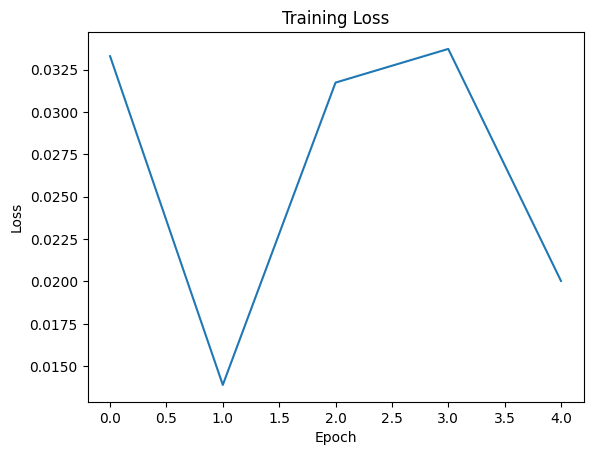

In [ ]:
import matplotlib.pyplot as plt

#plot training loss
plt.plot(epoch_losses)
plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()

In [ ]:
# Save the model's state dictionary to a file
torch.save(model.state_dict(), "/content/drive/My Drive/Colab Notebooks/mito_model_checkpoint.pth")

**Inference**

In [ ]:
from transformers import SamModel, SamConfig, SamProcessor
import torch

In [ ]:
# Load the model configuration
model_config = SamConfig.from_pretrained("facebook/sam-vit-base")
processor = SamProcessor.from_pretrained("facebook/sam-vit-base")

# Create an instance of the model architecture with the loaded configuration
my_mito_model = SamModel(config=model_config)
#Update the model by loading the weights from saved file.
my_mito_model.load_state_dict(torch.load("/content/drive/My Drive/Colab Notebooks/mito_model_checkpoint.pth"))

<All keys matched successfully>

In [ ]:
# set the device to cuda if available, otherwise use cpu
device = "cuda" if torch.cuda.is_available() else "cpu"
my_mito_model.to(device)

SamModel(
  (shared_image_embedding): SamPositionalEmbedding()
  (vision_encoder): SamVisionEncoder(
    (patch_embed): SamPatchEmbeddings(
      (projection): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
    )
    (layers): ModuleList(
      (0-11): 12 x SamVisionLayer(
        (layer_norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (attn): SamVisionAttention(
          (qkv): Linear(in_features=768, out_features=2304, bias=True)
          (proj): Linear(in_features=768, out_features=768, bias=True)
        )
        (layer_norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (mlp): SamMLPBlock(
          (lin1): Linear(in_features=768, out_features=3072, bias=True)
          (lin2): Linear(in_features=3072, out_features=768, bias=True)
          (act): GELUActivation()
        )
      )
    )
    (neck): SamVisionNeck(
      (conv1): Conv2d(768, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (layer_norm1): SamLayerNorm()
     

/usr/local/lib/python3.11/dist-packages/transformers/image_processing_utils.py:42: UserWarning: The following named arguments are not valid for `SamImageProcessor.preprocess` and were ignored: 'point_pad_value'
  return self.preprocess(images, **kwargs)


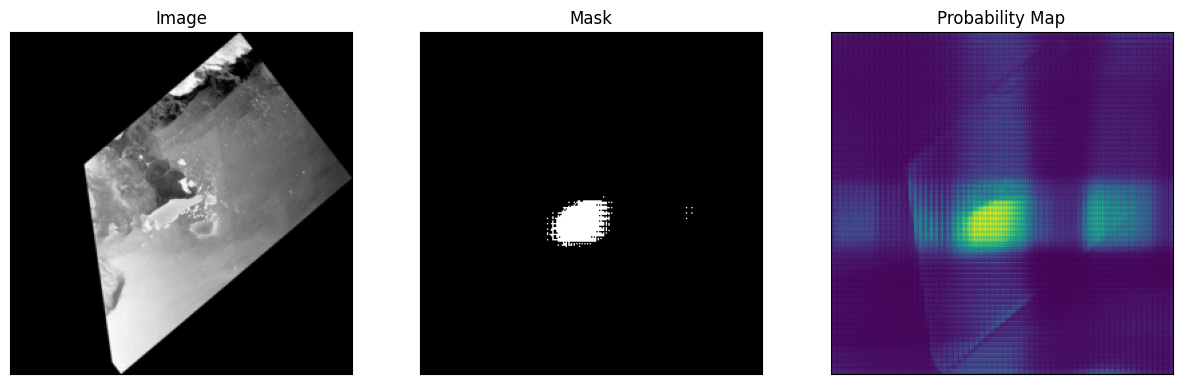

In [ ]:
import numpy as np
import random
import torch
import matplotlib.pyplot as plt

# let's take a random training example
idx = random.randint(0, len(dataset) - 1) #Generate a random index within the dataset

# load image
test_image = dataset[idx]["image"]

# get box prompt based on ground truth segmentation map
ground_truth_mask = np.array(dataset[idx]["label"])
prompt = get_bounding_box(ground_truth_mask)

# prepare image + box prompt for the model
inputs = processor(test_image, input_boxes=[[prompt]], return_tensors="pt")

# Move the input tensor to the GPU if it's not already there
inputs = {k: v.to(device) for k, v in inputs.items()}

my_mito_model.eval()

# forward pass
with torch.no_grad():
    outputs = my_mito_model(**inputs, multimask_output=False)

# apply sigmoid
medsam_seg_prob = torch.sigmoid(outputs.pred_masks.squeeze(1))
# convert soft mask to hard mask
medsam_seg_prob = medsam_seg_prob.cpu().numpy().squeeze()
medsam_seg = (medsam_seg_prob > 0.5).astype(np.uint8)


fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Plot the first image on the left
test_image_np = test_image.cpu().numpy()  # Move to CPU if necessary
test_image_np = test_image_np.transpose(1, 2, 0)  # Permute to (H, W, C)
axes[0].imshow(test_image_np, cmap='gray')  # Assuming the first image is grayscale
axes[0].set_title("Image")

# Plot the second image on the right
axes[1].imshow(medsam_seg, cmap='gray')  # Assuming the second image is grayscale
axes[1].set_title("Mask")

# Plot the second image on the right
axes[2].imshow(medsam_seg_prob)  # Assuming the second image is grayscale
axes[2].set_title("Probability Map")

# Hide axis ticks and labels
for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xticklabels([])
    ax.set_yticklabels([])

# Display the images side by side
plt.show()


In [ ]:
from sklearn.metrics import jaccard_score, f1_score

def compute_iou(y_true, y_pred):
    # Flatten the arrays to make them compatible for IoU calculation
    y_true = y_true.flatten()
    y_pred = y_pred.flatten()

    # Calculate Intersection over Union (IoU)
    return jaccard_score(y_true, y_pred)

def compute_dice_coefficient(y_true, y_pred):
    # Flatten the arrays to make them compatible for Dice coefficient calculation
    y_true = y_true.flatten()
    y_pred = y_pred.flatten()

    # Calculate Dice coefficient
    return 2 * np.sum(y_true * y_pred) / (np.sum(y_true) + np.sum(y_pred))

# Compute IoU and Dice for the current inference
iou = compute_iou(ground_truth_mask, medsam_seg)
dice = compute_dice_coefficient(ground_truth_mask, medsam_seg)

# Print the results
print(f"IoU: {iou:.4f}")
print(f"Dice Coefficient: {dice:.4f}")
